# RAG 1일차 (1) — RAG 개념과 전체 흐름 : 검색(Retrieval) + 증강(Augmented) + 생성(Generation)

교재 `AI Agent` 교재10 **p.34~38** (`24. RAG` — 생성형 AI 의 빛과 그림자 · RAG 정의와 흐름 · '지능형 고객 응대 Chatbot' 실습 개요) 를 정리하고, 그림 속 흐름을 **직접 돌려 본** 노트입니다.

```
[준비]  내 데이터 ─▶ 불러오기 ─▶ 분할(청크) ─▶ 임베딩(벡터) ─▶ 벡터 저장소
[질문]  질문 ─▶ 임베딩 ─▶ 저장소에서 가까운 청크 검색 ─▶ 질문 + 청크를 프롬프트에 넣기(증강) ─▶ LLM ─▶ 답변
```

- 오늘 수업에서 실제로 한 부분(불러오기 · 분할)은 [`rag_loader_text_splitter.ipynb`](./rag_loader_text_splitter.ipynb) 에 자세히 정리 (필기 `RAG_실습06` · `1RAG_실습1`)
- 📝 고친 부분은 맨 끝 표 · 그림은 [`images/`](./images/) 폴더

> **출력 읽는 법** — 정리 노트북은 **API 키 없이** 만들었다(Day 046 · 047 과 같은 방식).
>
> | 표시 | 뜻 |
> |---|---|
> | `# 🧪` | 진짜 임베딩 모델 대신 **글자 겹침으로 벡터를 만드는 대체 임베딩**으로 흐름만 실제로 돌린 셀 — 순위 · 점수는 `OpenAIEmbeddings` 결과와 다르다 |
> | `# ⏳` | API 키가 필요해 **출력이 비어 있는 셀** — 다음 수업(임베딩 · 벡터 저장소)에서 직접 실행 |
> | 표시 없음 | 정리 노트북에서 실제로 실행한 셀 (불러오기 · 분할 · 프롬프트 채우기 · 토큰 세기) |

In [1]:
# 한글 폰트 설정 (그래프 제목 · 축 이름이 깨지지 않게)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'      # 윈도우 : 맑은 고딕
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'        # macOS : 애플고딕
plt.rcParams['axes.unicode_minus'] = False             # 음수 부호(−)가 네모로 나오지 않게

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `langchain-community` · `faiss-cpu` | `TextLoader` · `FAISS` (벡터 저장소) | `pip install langchain-community faiss-cpu` |
| `langchain-text-splitters` · `langchain-core` | `RecursiveCharacterTextSplitter` · `ChatPromptTemplate` · `Embeddings` | `pip install langchain-text-splitters` |
| `langchain-openai` | `OpenAIEmbeddings` · `ChatOpenAI` (`# ⏳` 셀) | `pip install langchain-openai` |
| `scikit-learn` · `tiktoken` · `pandas` · `matplotlib` | 대체 임베딩(TF-IDF) · 토큰 세기 · 표 · 그래프 | `pip install scikit-learn tiktoken pandas matplotlib` |

**데이터** : 같은 폴더의 [`manual.txt`](./manual.txt). **실행** : 맨 위부터 모두 실행. `# ⏳` 셀만 `.env` 의 `OPENAI_API_KEY` 가 필요하다.

In [2]:
# ① 설치 (처음 한 번)
# !pip install -q langchain-community langchain-text-splitters langchain-openai faiss-cpu scikit-learn tiktoken pandas matplotlib

## 1. 생성형 AI : 빛과 그림자 (교재 p.35~36)

| 빛 (놀라운 능력) | 그림자 (치명적 약점) | RAG 가 채우는 방법 |
|---|---|---|
| 놀라운 창의력 — 글 · 그림 · 코드 | **환각**(Hallucination) — 그럴듯한 거짓말 | 답하기 전에 **근거 문서**를 찾아 프롬프트에 넣고 '이 안에서만 답하라' 고 한다 |
| 방대한 지식 — 세상의 온갖 정보를 학습 | **지식의 한계** — 특정 시점까지만 학습, 우리 회사 내부 자료는 모른다 | 학습을 다시 하지 않고 **최신 · 내부 데이터를 검색**해서 준다 |
| 유창한 소통 — 사람처럼 자연스럽게 | **출처 불분명** — 어떤 근거로 답했는지 모른다 | 검색된 문서의 `metadata`(파일 · 위치)를 **출처**로 함께 보여 준다 |

기업은 부정확하고 믿을 수 없는 AI 를 고객 응대 · 중요한 의사결정에 쓸 수 없다 → **가장 현실적인 대안이 RAG**.

오늘 실습의 '코드크래프터스 아카데미' 는 매뉴얼 속 회사다. LLM 은 이 회사의 환불 규정(결제 7일 이내 · 수강률 5% 미만)을 학습한 적이 없다 — 물어보면 **모른다고 하거나 지어낸다.** 규정이 적힌 `manual.txt` 를 찾아서 함께 줘야 맞는 답이 나온다.

## 2. RAG = 검색 + 증강 + 생성 (교재 p.37)

> **RAG system** — AI 가 답변하기 전, 기업의 내부 데이터나 최신 웹 정보 같은 **신뢰할 수 있는 자료를 먼저 검색**(Retrieval)하고, 이를 기반으로 답변을 **생성**(Generation)하여 AI 의 약점을 보완하는 기술

| 교재 그림의 번호 | 무슨 일 | 이 노트의 코드 |
|---|---|---|
| ① Prompt 와 Query | 사용자가 질문한다 | `question = '환불 받으려면 …'` |
| ② Query | 질문으로 지식 저장소를 **검색** | `vector_store.similarity_search(question)` |
| ③ 관련 정보 | 질문과 가까운 문서 조각(청크)이 돌아온다 | `[Document, …]` |
| ④ Prompt + Query + 컨텍스트 | 질문에 청크를 붙여 프롬프트를 만든다 = **증강** | `prompt.format_messages(context=…, question=…)` |
| ⑤ 생성된 응답 | LLM 이 그 프롬프트로 답한다 = **생성** | `llm.invoke(messages)` |

Day 047 의 검색 에이전트도 '검색 결과를 읽고 답한다' 는 점은 같았다. 차이는 **무엇을 검색하는가** — 그때는 웹(Tavily), RAG 는 **내가 미리 저장해 둔 문서**다. 그래서 RAG 에는 질문을 받기 전에 끝내 두는 **준비 단계**가 있다.

![RAG 흐름 애니메이션](./images/anim_01_rag_flow.gif)

## 3. 실습 개요 — 지능형 고객 응대 Chatbot (교재 p.38)

**목표** : 고객 응대 매뉴얼을 기반으로 RAG 시스템을 구축해 '지능형 고객 응대 전문 Chatbot' 을 구현한다.

| 교재 그림의 상자 | 역할 | LangChain 클래스 | 진도 |
|---|---|---|---|
| 내 데이터 | 고객 응대 매뉴얼 `manual.txt` | `TextLoader` → `Document` | ✅ 오늘 |
| (그림에 없음) | 긴 글을 검색하기 좋은 크기로 자른다 | `RecursiveCharacterTextSplitter` | ✅ 오늘 (도구 생성까지) |
| 임베딩 모델 | 글 → 벡터(숫자 목록) | `OpenAIEmbeddings` | 다음 |
| 벡터 DB (저장소) | 벡터를 저장하고 가까운 것을 찾는다 | `FAISS` | 다음 |
| Retriever | 질문 → 관련 청크 | `vector_store.as_retriever()` | 다음 |
| 언어 모델 | 질문 + 청크 → 답변 | `ChatPromptTemplate` · `ChatOpenAI` | 다음 |

교재 그림은 질문이 들어온 뒤의 화살표만 그렸다. 실제로는 '내 데이터' 를 **미리** 잘라 임베딩해서 저장소에 넣어 두고(준비), 질문이 오면 **질문만** 임베딩해서 저장소를 찾는다(질문).

## 4. 키 없이 흐름 한 바퀴 돌려 보기

오늘 만든 청크로 준비 → 검색 → 증강까지 실제로 실행한다. 임베딩 모델만 API 가 필요하므로 그 자리에 **대체 임베딩**을 끼운다.

### 4-1. 준비 ① ② — 불러오기 · 분할 (오늘 수업)

In [3]:
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)     # langchain-community 의 sunset 경고 (분할 노트 1장에 설명)

from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

documents = TextLoader('manual.txt', encoding='utf-8').load()                           # ① 파일 → [Document]
text_splitter = RecursiveCharacterTextSplitter(chunk_size=160, chunk_overlap=0)        # 수업 값
chunks = text_splitter.split_documents(documents)                                       # ② Document → 청크

for number, chunk in enumerate(chunks, 1):                 # 청크마다 번호를 metadata 에 적어 둔다 (검색 결과의 출처로 쓴다)
    chunk.metadata['chunk_id'] = number

print('Document :', len(documents), '개 ·', len(documents[0].page_content), '자')
print('청크     :', len(chunks), '개 ·', [len(c.page_content) for c in chunks])
print('metadata :', chunks[1].metadata)

Document : 1 개 · 1399 자
청크     : 10 개 · [133, 142, 146, 123, 157, 119, 116, 149, 149, 147]
metadata : {'source': 'manual.txt', 'chunk_id': 2}


### 4-2. 준비 ③ — 임베딩 : 글을 벡터로

**임베딩 모델**은 글을 받아 숫자 목록(벡터)을 돌려준다. 뜻이 비슷한 글은 벡터도 가깝게 나오도록 학습돼 있어서, '가까운 벡터 찾기' 가 곧 '뜻이 비슷한 글 찾기' 가 된다. LangChain 에서 임베딩 모델은 두 함수만 있으면 된다.

| 함수 | 입력 → 출력 | 언제 |
|---|---|---|
| `embed_documents(texts)` | 글 여러 개 → 벡터 여러 개 | 준비 단계 — 청크를 저장소에 넣을 때 |
| `embed_query(text)` | 글 1개 → 벡터 1개 | 질문 단계 — 질문을 벡터로 바꿀 때 |

아래 대체 임베딩은 뜻을 이해하지 못한다. **글자 2~3개 묶음이 얼마나 겹치는지**만 센다(TF-IDF). 흐름을 돌려 보는 용도다.

In [4]:
# 🧪 대체 임베딩 — OpenAIEmbeddings 자리에 끼울 수 있게 같은 함수 2개를 구현
from langchain_core.embeddings import Embeddings
from sklearn.feature_extraction.text import TfidfVectorizer

class CharNgramEmbeddings(Embeddings):
    # 글자 2~3개 묶음(n-gram)의 TF-IDF 벡터. 뜻이 아니라 '글자 겹침' 을 잰다
    def __init__(self, texts):
        self.vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 3)).fit(texts)    # 청크에 나온 묶음으로 사전을 만든다

    def embed_documents(self, texts):                       # 글 여러 개 → 벡터 여러 개
        return self.vectorizer.transform(texts).toarray().astype('float32').tolist()

    def embed_query(self, text):                            # 글 1개 → 벡터 1개
        return self.embed_documents([text])[0]

embeddings = CharNgramEmbeddings([c.page_content for c in chunks])

vector = embeddings.embed_query('환불 받으려면 어떻게 해야 하나요?')
print('벡터 길이(차원) :', len(vector))                                   # 사전에 든 묶음 수
print('0 이 아닌 칸    :', sum(v != 0 for v in vector), '개')              # 질문에 들어 있는 묶음만 값이 있다
print('앞 8칸          :', [round(v, 2) for v in vector[:8]])

벡터 길이(차원) : 1616
0 이 아닌 칸    : 22 개
앞 8칸          : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


### 4-3. 준비 ④ — 벡터 저장소 `FAISS`

In [5]:
# 🧪 청크 10개를 임베딩해서 FAISS 에 저장 (임베딩 모델만 대체품)
from langchain_community.vectorstores import FAISS

vector_store = FAISS.from_documents(chunks, embeddings)      # 내부에서 embeddings.embed_documents() 호출 → 벡터 저장

print('저장된 벡터 수 :', vector_store.index.ntotal)          # 청크 수와 같다
print('벡터 차원      :', vector_store.index.d)
print('인덱스 종류    :', type(vector_store.index).__name__)  # IndexFlatL2 : 모든 벡터와 거리를 직접 계산

저장된 벡터 수 : 10
벡터 차원      : 1616
인덱스 종류    : IndexFlatL2


### 4-4. 질문 ② ③ — 검색(Retrieval)

In [6]:
# 🧪 질문과 가까운 청크 찾기 — 점수는 거리(L2 제곱)라서 작을수록 가깝다
import pandas as pd

question = '환불 받으려면 어떻게 해야 하나요?'
results = vector_store.similarity_search_with_score(question, k=len(chunks))    # 10개 전부 순위대로

ranking = pd.DataFrame([{
    '순위': rank,
    'QA 번호': doc.metadata['chunk_id'],                       # 몇 번째 청크인가 (4-1 에서 적어 둔 번호)
    '거리': round(float(score), 3),
    '코사인 유사도': round(1 - float(score) / 2, 3),            # 길이 1 인 벡터끼리는 거리 = 2 − 2·cos
    '질문 줄': doc.page_content.split('\n')[0][4:],
} for rank, (doc, score) in enumerate(results, 1)]).set_index('순위')
ranking

,QA 번호,거리,코사인 유사도,질문 줄
순위,,,,
1,2,1.590,0.205,수강 신청한 강의를 환불하고 싶어요. 환불 정책은 어떻게 되나요?
2,1,1.767,0.117,코드크래프터스 아카데미에 어떻게 가입하나요?
3,8,1.791,0.104,코딩 실습 중에 모르는 것이 생기면 어떻게 하죠?
4,3,1.838,0.081,강의를 다 들으면 수료증을 받을 수 있나요?
5,9,1.937,0.031,"선수 지식이 없는데, 어떤 강의부터 들어야 할지 모르겠어요."
6,6,1.938,0.031,강의 자료나 소스 코드는 어디서 다운로드받나요?
7,7,1.960,0.020,수강 기간에 제한이 있나요?
8,10,1.965,0.018,모바일 앱으로도 강의를 들을 수 있나요?
9,4,1.965,0.017,어떤 결제 수단을 사용할 수 있나요?


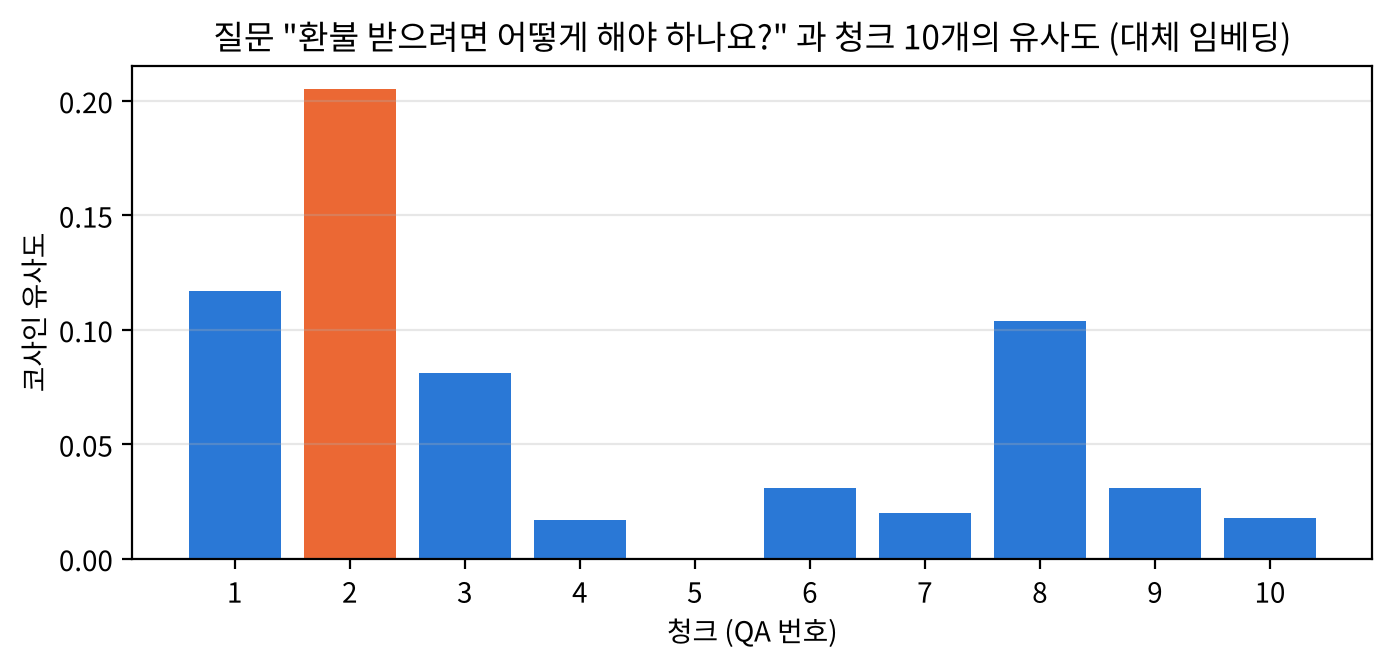

In [7]:
# 🧪 유사도를 막대로 — 1등과 2등의 차이를 본다
order = ranking.sort_values('QA 번호')
colors = ['#eb6834' if n == ranking.loc[1, 'QA 번호'] else '#2a78d6' for n in order['QA 번호']]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(order['QA 번호'].astype(str), order['코사인 유사도'], color=colors)
ax.set_xlabel('청크 (QA 번호)'); ax.set_ylabel('코사인 유사도')
ax.set_title(f'질문 "{question}" 과 청크 10개의 유사도 (대체 임베딩)')
ax.grid(axis='y', alpha=0.3)
plt.show()

1등은 **2번 청크(환불 QA)** 다. 질문의 `환불` · `어떻게` 같은 글자 묶음이 그 청크에 가장 많이 들어 있기 때문이다. 유사도 값 자체는 0.2 정도로 낮고 2등과의 차이도 크지 않다 — 대체 임베딩의 한계는 5장 실험 B 에서 본다.

`as_retriever()` 는 저장소를 '질문 → 문서 목록' 도구(검색 도구, Retriever)로 감싼다. 체인에 끼울 때 이 형태를 쓴다.

In [8]:
# 🧪 검색 도구(Retriever) — 질문을 넣으면 가까운 청크 k 개를 돌려준다
retriever = vector_store.as_retriever(search_kwargs={'k': 2})      # 위에서 2개만
retrieved = retriever.invoke(question)

for doc in retrieved:
    print(doc.metadata, '|', len(doc.page_content), '자')
    print(doc.page_content)
    print('-' * 60)

{'source': 'manual.txt', 'chunk_id': 2} | 142 자
질문: 수강 신청한 강의를 환불하고 싶어요. 환불 정책은 어떻게 되나요?
답변: 네, 환불 가능합니다. 결제일로부터 7일 이내, 그리고 강의 수강률이 5% 미만일 경우 전액 환불해 드리고 있습니다. 고객센터를 통해 문의하시면 신속하게 처리해 드리겠습니다.
------------------------------------------------------------
{'source': 'manual.txt', 'chunk_id': 1} | 133 자
질문: 코드크래프터스 아카데미에 어떻게 가입하나요?
답변: 저희 웹사이트 우측 상단의 '회원가입' 버튼을 클릭하시고, 이메일 주소와 비밀번호만 입력하면 간단하게 가입이 완료됩니다. 이메일 인증 후 바로 모든 서비스를 이용하실 수 있습니다.
------------------------------------------------------------


### 4-5. 질문 ④ — 증강(Augmented) : 검색된 청크를 프롬프트에 넣는다

'증강' 은 특별한 연산이 아니다. **검색된 글을 프롬프트의 정해진 자리에 붙여 넣는 것**이다.

In [9]:
from langchain_core.prompts import ChatPromptTemplate

rag_prompt = ChatPromptTemplate.from_messages([
    ('system', '너는 코드크래프터스 아카데미의 고객 응대 챗봇이야. '
               '아래 [매뉴얼]에 있는 내용만 근거로 답하고, 매뉴얼에 없으면 "매뉴얼에 없는 내용입니다"라고 답해.\n\n'
               '[매뉴얼]\n{context}'),                               # ← 검색된 청크가 들어갈 자리
    ('user', '{question}'),                                         # ← 사용자의 질문
])

context = '\n\n'.join(doc.page_content for doc in retrieved)        # 청크 2개를 빈 줄로 이어 붙인다
messages = rag_prompt.format_messages(context=context, question=question)

for m in messages:                                                   # LLM 에 실제로 보내질 내용
    print(f'[{type(m).__name__}]')
    print(m.content)
    print()

[SystemMessage]
너는 코드크래프터스 아카데미의 고객 응대 챗봇이야. 아래 [매뉴얼]에 있는 내용만 근거로 답하고, 매뉴얼에 없으면 "매뉴얼에 없는 내용입니다"라고 답해.

[매뉴얼]
질문: 수강 신청한 강의를 환불하고 싶어요. 환불 정책은 어떻게 되나요?
답변: 네, 환불 가능합니다. 결제일로부터 7일 이내, 그리고 강의 수강률이 5% 미만일 경우 전액 환불해 드리고 있습니다. 고객센터를 통해 문의하시면 신속하게 처리해 드리겠습니다.

질문: 코드크래프터스 아카데미에 어떻게 가입하나요?
답변: 저희 웹사이트 우측 상단의 '회원가입' 버튼을 클릭하시고, 이메일 주소와 비밀번호만 입력하면 간단하게 가입이 완료됩니다. 이메일 인증 후 바로 모든 서비스를 이용하실 수 있습니다.

[HumanMessage]
환불 받으려면 어떻게 해야 하나요?



In [10]:
# 프롬프트 크기 비교 — 검색된 청크만 넣을 때 vs 매뉴얼을 통째로 넣을 때
import tiktoken
enc = tiktoken.get_encoding('o200k_base')                            # 대략적인 토큰 수 계산용

def prompt_tokens(context_text):
    filled = rag_prompt.format_messages(context=context_text, question=question)
    return sum(len(enc.encode(m.content)) for m in filled)

rag_tokens = prompt_tokens(context)                                  # 청크 2개
full_tokens = prompt_tokens(documents[0].page_content)               # 매뉴얼 전체
print(f'검색된 청크 2개 : 약 {rag_tokens:,} 토큰')
print(f'매뉴얼 전체     : 약 {full_tokens:,} 토큰  ({full_tokens / rag_tokens:.1f}배)')

검색된 청크 2개 : 약 225 토큰
매뉴얼 전체     : 약 857 토큰  (3.8배)


- 이 매뉴얼은 QA 10쌍뿐이라 **통째로 넣어도** 프롬프트가 약 860 토큰이다. 이 크기라면 검색 없이 전부 넣는 것이 더 간단하고 빠뜨릴 위험도 없다
- RAG 가 꼭 필요해지는 것은 문서가 **수백 · 수천 쪽**이 돼 프롬프트에 다 넣을 수 없거나, 넣을 수는 있어도 질문마다 그 비용을 치르기 아까울 때다. 오늘 실습은 그 방법을 작은 데이터로 연습하는 것이다

### 4-6. 질문 ⑤ — 생성(Generation)

마지막은 이 메시지를 LLM 에 보내는 것뿐이다. API 키가 필요하다.

In [ ]:
# ⏳ 증강된 프롬프트로 답 생성 — .env 의 OPENAI_API_KEY 필요
from dotenv import load_dotenv, find_dotenv
from langchain_openai import ChatOpenAI

load_dotenv(find_dotenv(usecwd=True))
llm = ChatOpenAI(model='gpt-5-nano')            # Day 047 과 같은 모델
answer = llm.invoke(messages)                   # 위에서 만든 [System(매뉴얼 포함), Human(질문)]
print(answer.content)

## 5. 비교 실험

### 실험 A — `chunk_size` 가 검색 결과를 바꾼다

같은 질문으로, 청크 크기만 바꿔 1등 청크를 비교한다. (왜 QA 1쌍 = 청크 1개로 자르는지의 답)

In [11]:
# 🧪 chunk_size 별로 저장소를 새로 만들고 같은 질문의 1등 청크를 본다
def top_chunk(chunk_size, query):
    parts = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=0).split_documents(documents)
    store = FAISS.from_documents(parts, CharNgramEmbeddings([p.page_content for p in parts]))
    doc, score = store.similarity_search_with_score(query, k=1)[0]
    return len(parts), doc.page_content

rows = []
for size in [100, 160, 300, 4000]:
    n_chunks, text = top_chunk(size, question)
    rows.append({
        'chunk_size': size,
        '청크 수': n_chunks,
        '1등 청크 글자 수': len(text),
        '든 질문 수': text.count('질문:'),
        '환불 규정(7일) 포함': '7일' in text,                  # 답에 필요한 내용이 들어 있는가
        '1등 청크 앞부분': text[:30].replace('\n', ' '),
    })
pd.DataFrame(rows).set_index('chunk_size')

,청크 수,1등 청크 글자 수,든 질문 수,환불 규정(7일) 포함,1등 청크 앞부분
chunk_size,,,,,
100,27,28,1,False,질문: 코드크래프터스 아카데미에 어떻게 가입하나요?
160,10,142,1,True,질문: 수강 신청한 강의를 환불하고 싶어요. 환불 정책
300,5,277,2,True,질문: 코드크래프터스 아카데미에 어떻게 가입하나요? 답
4000,1,1399,10,True,질문: 코드크래프터스 아카데미에 어떻게 가입하나요? 답


| `chunk_size` | 1등으로 검색된 것 | 문제 |
|---|---|---|
| 100 | '질문: … 어떻게 가입하나요?' **질문 줄만**(28자) | 질문과 답변이 갈라져 **답(7일 · 5%)이 없다.** 질문끼리 말투가 비슷해 엉뚱한 질문 줄이 뽑혔다 |
| **160** | 환불 QA 한 쌍(142자) | 필요한 내용만 정확히 |
| 300 | 가입 QA + 환불 QA 가 합쳐진 청크(277자) | 답은 있지만 절반은 상관없는 내용 |
| 4000 | 매뉴얼 전체(1,399자) | 어떤 질문이든 같은 것이 나온다 — 검색의 의미가 없다 |

![chunk_size 별 검색 결과 애니메이션](./images/anim_05_retrieval_by_chunk_size.gif)

### 실험 B — 대체 임베딩의 한계 : 글자가 달라지면 찾지 못한다

뜻은 같지만 매뉴얼과 **다른 낱말**로 물어본다.

In [12]:
# 🧪 (질문, 정답 QA 번호) — 앞 6개는 매뉴얼과 낱말이 겹치고, 뒤 6개는 뜻만 같다
tests = [
    ('환불 받으려면 어떻게 해야 하나요?', 2), ('수료증은 언제 나오나요?', 3), ('카드로 결제할 수 있나요?', 4),
    ('영상이 계속 멈춰요', 5), ('강의는 언제까지 볼 수 있나요?', 7), ('처음인데 뭐부터 들어야 해요?', 9),
    ('돈 돌려줘', 2), ('완강하면 뭐 줘요?', 3), ('버퍼링이 심해요', 5),
    ('핸드폰 지원돼?', 10), ('스마트폰에서 시청 가능?', 10), ('자격증 나와요?', 3),
]

rows = []
for query, answer_id in tests:
    doc, score = vector_store.similarity_search_with_score(query, k=1)[0]
    found_id = doc.metadata['chunk_id']
    nonzero = sum(v != 0 for v in embeddings.embed_query(query))          # 질문 벡터에서 값이 있는 칸 수
    rows.append({'질문': query, '정답': answer_id, '1등': found_id, '맞음': found_id == answer_id,
                 '거리': round(float(score), 3), '겹친 묶음 수': nonzero})
result_b = pd.DataFrame(rows)
print('낱말이 겹치는 질문 :', result_b['맞음'][:6].sum(), '/ 6   |   뜻만 같은 질문 :', result_b['맞음'][6:].sum(), '/ 6')
result_b

낱말이 겹치는 질문 : 6 / 6   |   뜻만 같은 질문 : 0 / 6


,질문,정답,1등,맞음,거리,겹친 묶음 수
0,환불 받으려면 어떻게 해야 하나요?,2,2,True,1.590,22
1,수료증은 언제 나오나요?,3,3,True,1.524,15
2,카드로 결제할 수 있나요?,4,4,True,1.391,18
3,영상이 계속 멈춰요,5,5,True,1.728,6
4,강의는 언제까지 볼 수 있나요?,7,7,True,1.507,22
5,처음인데 뭐부터 들어야 해요?,9,9,True,1.479,13
6,돈 돌려줘,2,9,False,1.000,0
7,완강하면 뭐 줘요?,3,1,False,1.786,4
8,버퍼링이 심해요,5,7,False,1.832,1
9,핸드폰 지원돼?,10,5,False,1.829,3


- 매뉴얼과 낱말이 겹치는 질문은 6개 모두 맞혔고, **뜻만 같은 질문은 6개 모두 틀렸다**
- `돈 돌려줘` 는 겹친 묶음이 **0개** — 질문 벡터가 전부 0 이라 모든 청크와 거리가 똑같이 1.0 이다. 1등은 아무 의미가 없다
- `환불` ↔ `돈 돌려줘`, `모바일` ↔ `핸드폰`, `수료증` ↔ `자격증` 을 같은 것으로 보려면 **뜻을 학습한 임베딩 모델**이 필요하다 → 다음 수업의 `OpenAIEmbeddings`. (같은 12개 질문을 그때 다시 넣어 본다)

## 6. 다음 수업 미리 보기 — 진짜 임베딩으로 바꾸기

바꿀 곳은 **임베딩 한 줄**이다. 나머지(`FAISS.from_documents` · `as_retriever` · 프롬프트)는 위와 같다.

In [ ]:
# ⏳ OpenAIEmbeddings + FAISS + 프롬프트 + LLM = RAG 체인 — .env 의 OPENAI_API_KEY 필요
from dotenv import load_dotenv, find_dotenv
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough

load_dotenv(find_dotenv(usecwd=True))

real_embeddings = OpenAIEmbeddings(model='text-embedding-3-small')             # 글 → 1,536차원 벡터 (API 호출)
real_store = FAISS.from_documents(chunks, real_embeddings)                     # 청크 10개 임베딩 → 저장
real_retriever = real_store.as_retriever(search_kwargs={'k': 2})               # 검색 도구

def format_docs(docs):                                                         # [Document] → 프롬프트에 넣을 글
    return '\n\n'.join(doc.page_content for doc in docs)

rag_chain = (
    {'context': real_retriever | format_docs, 'question': RunnablePassthrough()}   # 질문 → 검색 → context / 질문 그대로 → question
    | rag_prompt                                                                    # 증강
    | ChatOpenAI(model='gpt-5-nano')                                                # 생성
    | StrOutputParser()
)
print(rag_chain.invoke('돈 돌려줘'))        # 실험 B 에서 대체 임베딩이 찾지 못한 질문

## 📝 고친 부분 정리 (교재 p.34~38)

| 위치 | 교재 | 고친 내용 · 덧붙인 내용 |
|---|---|---|
| p.34 제목 | `Retrieval Augmented Generation` | 원 논문(Lewis et al., 2020) 표기는 **`Retrieval-Augmented Generation`** (하이픈). 교재도 p.39 에서는 하이픈을 쓴다 |
| p.36 ~ 37 | RAG 가 'AI 의 약점을 보완' | 환각을 **줄이지만 없애지는 못한다.** Day 047 에이전트는 검색 결과를 받고도 한 문장의 뜻을 거꾸로 옮겼다 → 근거를 줘도 답은 검토한다 |
| p.37 그림 ③ | '증강된 컨텍스트(관련정보)' 가 저장소에서 돌아옴 | 저장소가 돌려주는 것은 **검색된** 관련 정보. '증강' 은 그것을 프롬프트에 붙이는 ④ 단계 |
| p.38 그림 | 질문이 들어온 뒤 벡터 DB 가 '내 데이터' 를 lookup | 내 데이터는 **미리** 분할 · 임베딩해 저장해 둔다(준비 단계). 질문 때는 질문만 임베딩한다. 그림에는 **분할 단계가 없다** |
| p.38 | 실습 목표만 제시 | 매뉴얼을 통째로 넣어도 프롬프트가 약 860 토큰 — 이 크기는 검색 없이 전부 넣어도 된다. RAG 는 문서가 커질 때 필요한 방법을 작은 데이터로 연습하는 것 |
| 머리글 | `SK네트웍스 Famiy` | Family |

## 정리

| 단계 | 한 일 | 코드 | 오늘 결과 |
|---|---|---|---|
| 준비 ① | 불러오기 | `TextLoader(…).load()` | Document 1개 · 1,399자 |
| 준비 ② | 분할 | `RecursiveCharacterTextSplitter(chunk_size=160, chunk_overlap=0)` | 청크 10개 = QA 10쌍 |
| 준비 ③ ④ | 임베딩 · 저장 | `FAISS.from_documents(chunks, embeddings)` | 🧪 대체 임베딩으로 벡터 10개 |
| 질문 ② ③ | 검색 | `retriever.invoke(question)` | 🧪 '환불 …' → 2번 청크 |
| 질문 ④ | 증강 | `rag_prompt.format_messages(context=…, question=…)` | 시스템 메시지에 청크 2개 |
| 질문 ⑤ | 생성 | `llm.invoke(messages)` | ⏳ 다음 수업 |